**Live Deployment Link:** [PASTE YOUR STREAMLIT LINK HERE]

**GitHub Repository:** [PASTE YOUR GITHUB REPO LINK HERE]

# Titanic Passenger Survival Prediction System
**AIC354 - Machine Learning Fundamentals | Assignment 2, Task 1** &nbsp;|&nbsp; Yasir Hussain Bukhari (FA24-BCS-132)

## About This Notebook

This is **Task 1** of Assignment 2: run and understand the instructor-provided Titanic Passenger Survival Prediction System, then deploy the trained model to the cloud.

The original code, data and teaching structure come from the instructor's repository (`haqnawaz99/ml-teaching-notebooks`, developed under Dr. Rao Muhammad Adeel Nawab). In this copy I:

- ran every step on my own machine and wrote the explanations in my own words,
- printed the Label Encoder mappings so the numbers are easy to follow,
- replaced the fixed demo passenger with a small table of passengers, and
- built the Step 9 feedback example from the model's real predictions instead of typing the results by hand.

The modelling approach (Label Encoding + Support Vector Classifier) is unchanged.

## Introduction

**Definition:** A binary classification task. Given four facts about a Titanic passenger, the model predicts whether the passenger **survived (Yes)** or **did not survive (No)**.

**Application:** Mainly used for learning: it shows the complete machine learning cycle on a small, easy dataset, and it shows how factors such as class and gender relate to survival.

## Input and Output

### Inputs (Features / Attributes)

| **Input Attribute** | **Possible Values** |
| --- | --- |
| **PClass** | First, Second, Third |
| **Gender** | Male, Female |
| **Sibling** (siblings/spouses aboard) | Zero, One, Two, Three |
| **Embarked** (port) | Southampton, Cherbourg, Queenstown |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **Survived** | Yes, No |

### Examples from the dataset (first 5 rows)

| PClass | Gender | Sibling | Embarked | Survived |
| :--- | :--- | :--- | :--- | :--- |
| Third | Male | One | Southampton | No |
| Second | Female | Zero | Southampton | Yes |
| Third | Male | Zero | Southampton | No |
| Third | Female | Three | Southampton | Yes |
| Third | Male | Zero | Queenstown | No |

## Developer & System Information

| | |
| --- | --- |
| **Developer** | Yasir Hussain Bukhari |
| **Registration No.** | FA24-BCS-132 |
| **Course** | Machine Learning Fundamentals (AIC354), Dr. Jawad Shafi |
| **Original code and data** | Mr. Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab (instructor-provided) |
| **Program Name** | titanic_project |
| **IDE** | Jupyter Notebook |
| **Language** | Python 3.12 |
| **Libraries** | NumPy 2.1.3, Pandas 2.2.3, scikit-learn 1.6.1, Pickle (built-in), PrettyTable, Matplotlib, Seaborn |
| **Deployment** | Streamlit Community Cloud (see Step 10) |
| **Date of Completion** | 17-Oct-2026 |

## Table of Contents
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding (5.1 train the encoders, 5.2 encode the output, 5.3 encode the input)
- Step 6: Training Phase (split, separate inputs/labels, train SVC, save model)
- Step 7: Testing Phase (load model, predict, accuracy, precision/recall/F1, confusion matrix)
- Step 8: Application Phase (input, feature vector, encoding, prediction)
- Step 9: Feedback Phase
- Step 10: Deploy the Model on the Cloud
- Conclusion

## Code: Titanic Passenger Survival Prediction

### Step 1: Import Libraries

In [1]:
# Notebook-only extras (the deployed web app does not need these).
%pip install -q prettytable matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np                       # arrays and numeric helpers
import pandas as pd                      # tables (DataFrames) and CSV reading
import pickle                            # save / load the trained model
import matplotlib.pyplot as plt          # plotting
import seaborn as sns                    # nicer heatmap for the confusion matrix

from sklearn.model_selection import train_test_split          # training / testing split
from sklearn.preprocessing import LabelEncoder                 # text -> number codes
from sklearn import svm                                        # Support Vector Classifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable                            # neat final prediction table

### Step 2: Load Sample Data
The sample data is a CSV file with 100 passengers. Each row is one passenger and the last column (`Survived`) is the answer the model must learn to predict.

In [3]:
sample_data = pd.read_csv("sample-data.csv")

print("Sample Data (first 10 rows):")
print("============================\n")
print(sample_data.head(10))
print("\nShape (rows, columns):", sample_data.shape)

Sample Data (first 10 rows):

   PClass  Gender Sibling     Embarked Survived
0   Third    Male     One  Southampton       No
1  Second  Female    Zero  Southampton      Yes
2   Third    Male    Zero  Southampton       No
3   Third  Female   Three  Southampton      Yes
4   Third    Male    Zero   Queenstown       No
5   First  Female   Three  Southampton      Yes
6   Third    Male    Zero  Southampton       No
7   Third    Male    Zero  Southampton      Yes
8   First    Male    Zero  Southampton       No
9  Second    Male    Zero  Southampton      Yes

Shape (rows, columns): (100, 5)


### Step 3: Understand and Pre-process Sample Data
#### Step 3.1: Understand Sample Data

In [4]:
print("Attributes in Sample Data:")
print("==========================")
print(list(sample_data.columns))

print("\nNumber of instances:", len(sample_data))

print("\nHow many times does each value appear?")
print("======================================")
for column in sample_data.columns:
    print(column, "->", sample_data[column].value_counts().to_dict())

Attributes in Sample Data:
['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived']

Number of instances: 100

How many times does each value appear?
PClass -> {'Third': 60, 'Second': 20, 'First': 20}
Gender -> {'Male': 58, 'Female': 42}
Sibling -> {'Zero': 59, 'One': 29, 'Three': 6, 'Two': 6}
Embarked -> {'Southampton': 75, 'Cherbourg': 16, 'Queenstown': 9}
Survived -> {'No': 50, 'Yes': 50}


**What this tells us:** all five columns are text categories (no numbers yet). The output is perfectly balanced: 50 passengers survived and 50 did not, so accuracy is a fair first measure here.

#### Step 3.2: Pre-process Sample Data
Pre-processing means fixing missing values or messy entries. Let's check whether any fixing is needed.

In [5]:
print("Missing values per column:")
print(sample_data.isnull().sum())

# Are all values from the expected lists? (anything unexpected would be printed)
allowed_values = {"PClass": ["First", "Second", "Third"],
                  "Gender": ["Male", "Female"],
                  "Sibling": ["Zero", "One", "Two", "Three"],
                  "Embarked": ["Southampton", "Cherbourg", "Queenstown"],
                  "Survived": ["Yes", "No"]}
print("\nUnexpected values per column:")
for column, allowed in allowed_values.items():
    print(column, "->", sorted(set(sample_data[column]) - set(allowed)) or "none")

Missing values per column:
PClass      0
Gender      0
Sibling     0
Embarked    0
Survived    0
dtype: int64

Unexpected values per column:
PClass -> none
Gender -> none
Sibling -> none
Embarked -> none
Survived -> none


There are **no missing values**, and every value already belongs to the allowed list, so **no pre-processing is required**.

### Step 4: Feature Extraction
The four input attributes are already clean categories that can be used directly, so **no feature extraction is required**.

### Step 5: Label Encoding
Machine learning models work with numbers, not words. **Label Encoding** gives every text value its own whole-number code.

#### Step 5.1: Train the Label Encoders

In [6]:
# All possible values of every attribute (this list is what the web app uses too)
pclass_values   = ["First", "Second", "Third"]
gender_values   = ["Male", "Female"]
sibling_values  = ["Zero", "One", "Two", "Three"]
embarked_values = ["Southampton", "Cherbourg", "Queenstown"]
survived_values = ["Yes", "No"]

# One encoder per attribute, trained (fit) on its list of values
pclass_label_encoder   = LabelEncoder().fit(np.ravel(pclass_values))
gender_label_encoder   = LabelEncoder().fit(np.ravel(gender_values))
sibling_label_encoder  = LabelEncoder().fit(np.ravel(sibling_values))
embarked_label_encoder = LabelEncoder().fit(np.ravel(embarked_values))
survived_label_encoder = LabelEncoder().fit(np.ravel(survived_values))

# Show which number each word received (codes follow alphabetical order)
for name, encoder in [("PClass", pclass_label_encoder), ("Gender", gender_label_encoder),
                      ("Sibling", sibling_label_encoder), ("Embarked", embarked_label_encoder),
                      ("Survived", survived_label_encoder)]:
    print(f"{name:9}", {str(word): int(code) for word, code in zip(encoder.classes_, encoder.transform(encoder.classes_))})

PClass    {'First': 0, 'Second': 1, 'Third': 2}
Gender    {'Female': 0, 'Male': 1}
Sibling   {'One': 0, 'Three': 1, 'Two': 2, 'Zero': 3}
Embarked  {'Cherbourg': 0, 'Queenstown': 1, 'Southampton': 2}
Survived  {'No': 0, 'Yes': 1}


#### Step 5.2: Label Encode the Output

In [7]:
sample_data_encoded_output = sample_data.copy()
sample_data_encoded_output["Survived"] = survived_label_encoder.transform(sample_data["Survived"])

print("Output attribute before and after encoding (first 6 rows):")
print(pd.DataFrame({"Survived (text)": sample_data["Survived"].head(6),
                    "Survived (code)": sample_data_encoded_output["Survived"].head(6)}))

sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False)
print("\nSaved: sample-data-encoded-output.csv")

Output attribute before and after encoding (first 6 rows):
  Survived (text)  Survived (code)
0              No                0
1             Yes                1
2              No                0
3             Yes                1
4              No                0
5             Yes                1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [8]:
sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded["PClass"]   = pclass_label_encoder.transform(sample_data["PClass"])
sample_data_encoded["Gender"]   = gender_label_encoder.transform(sample_data["Gender"])
sample_data_encoded["Sibling"]  = sibling_label_encoder.transform(sample_data["Sibling"])
sample_data_encoded["Embarked"] = embarked_label_encoder.transform(sample_data["Embarked"])

print("Sample data after Label Encoding (first 10 rows):")
print(sample_data_encoded.head(10))

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False)
print("\nSaved: sample-data-encoded.csv")

Sample data after Label Encoding (first 10 rows):
   PClass  Gender  Sibling  Embarked  Survived
0       2       1        0         2         0
1       1       0        3         2         1
2       2       1        3         2         0
3       2       0        1         2         1
4       2       1        3         1         0
5       0       0        1         2         1
6       2       1        3         2         0
7       2       1        3         2         1
8       0       1        3         2         0
9       1       1        3         2         1

Saved: sample-data-encoded.csv


### Step 6: Execute the Training Phase
#### Step 6.1: Split Sample Data into Training Data and Testing Data
80% of the rows teach the model; the other 20% are kept hidden and used later to check it. As in the instructor's code, rows are **not** shuffled (`shuffle=False`), so the last 20 rows become the test set.

In [9]:
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded, test_size=0.2, random_state=0, shuffle=False)

training_data_encoded.to_csv("training-data-encoded.csv", index=False)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False)

print("Training data shape:", training_data_encoded.shape)
print("Testing data shape: ", testing_data_encoded.shape)

Training data shape: (80, 5)
Testing data shape:  (20, 5)


#### Step 6.2: Split Input Vectors and Labels of Training Data
Every column except the last is an input; the last column is the label.

In [10]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train):", input_vector_train.shape)
print("Output labels (train):", output_label_train.shape)

Input vectors (train): (80, 4)
Output labels (train): (80,)


#### Step 6.3: Train the Support Vector Classifier
A Support Vector Classifier (SVC) finds the boundary that best separates the two classes (survived / not survived).

In [11]:
svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print("Trained model:", svc_model)

Trained model: SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model
Saving the model in a `.pkl` file means it can be reused (including by the web app) without training again.

In [12]:
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase
#### Step 7.1: Split Input Vectors and Labels of Testing Data

In [13]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test):", input_vector_test.shape)
print("Output labels (test):", output_label_test.shape)

Input vectors (test): (20, 4)
Output labels (test): (20,)


#### Step 7.2: Load the Saved Model

In [14]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl

#### Step 7.3: Evaluate the Model
##### Step 7.3.1: Make Predictions on the Testing Data

In [15]:
testing_data_encoded = testing_data_encoded.copy()
testing_data_encoded["Predictions"] = model.predict(input_vector_test)
testing_data_encoded.to_csv("model-predictions.csv", index=False)

model_predictions = testing_data_encoded
print("Predictions on the 20 testing passengers (codes: 0 = No, 1 = Yes):")
print(model_predictions)

Predictions on the 20 testing passengers (codes: 0 = No, 1 = Yes):


    PClass  Gender  Sibling  Embarked  Survived  Predictions
80       2       1        2         2         0            0
81       2       0        3         2         1            1
82       2       1        3         2         0            0
83       0       1        0         2         1            0
84       1       1        3         2         0            0
85       2       0        0         1         1            1
86       1       1        3         2         0            0
87       0       0        0         2         1            1
88       2       1        3         2         0            0
89       1       0        3         2         1            1
90       1       1        3         2         0            0
91       1       0        3         2         1            1
92       2       1        3         0         0            0
93       0       1        0         2         1            0
94       0       1        0         2         0            0
95       2       1     

#### Step 7.4: Calculate the Accuracy Score
Accuracy = correct predictions / total predictions.

In [16]:
model_accuracy_score = accuracy_score(model_predictions["Survived"], model_predictions["Predictions"])
print("Accuracy Score:", round(model_accuracy_score, 2))

Accuracy Score: 0.8


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
Accuracy alone hides *which* mistakes are made, so we also look at:
- **Precision:** of the passengers predicted as a class, how many really were in it?
- **Recall:** of the passengers who really were in a class, how many did the model find?
- **F1-score:** one number that balances precision and recall.
- **Confusion matrix:** a table of correct and wrong predictions for each class.

Classification Report


                  precision    recall  f1-score   support

Not Survived (0)       0.71      1.00      0.83        10
    Survived (1)       1.00      0.60      0.75        10

        accuracy                           0.80        20
       macro avg       0.86      0.80      0.79        20
    weighted avg       0.86      0.80      0.79        20



Confusion Matrix
                      Predicted: Not Survived  Predicted: Survived
Actual: Not Survived                       10                    0
Actual: Survived                            4                    6


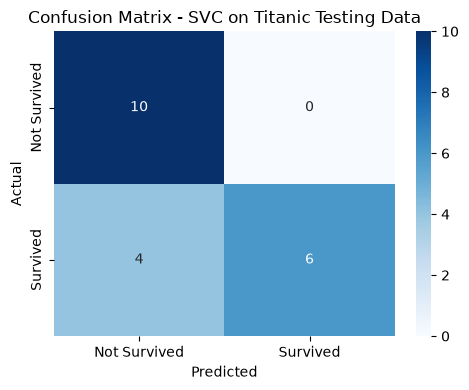

In [17]:
print("Classification Report")
print("=====================")
print(classification_report(model_predictions["Survived"], model_predictions["Predictions"],
                            target_names=["Not Survived (0)", "Survived (1)"]))

conf_matrix = confusion_matrix(model_predictions["Survived"], model_predictions["Predictions"])
print("Confusion Matrix")
print("================")
print(pd.DataFrame(conf_matrix,
                   index=["Actual: Not Survived", "Actual: Survived"],
                   columns=["Predicted: Not Survived", "Predicted: Survived"]))

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Survived", "Survived"], yticklabels=["Not Survived", "Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Titanic Testing Data")
plt.tight_layout()
plt.show()

**Reading the result:** accuracy is **0.80**. The model finds **100%** of the passengers who did not survive (recall 1.00) but only **60%** of those who survived (recall 0.60). When it says "Survived" it is right **100%** of the time (precision 1.00), whereas "Not Survived" predictions are right 71% of the time (precision 0.71). In short, the model is cautious: it tends to predict "Not Survived".

### Step 8: Execute the Application Phase
This is the phase that real users see: new passenger details go in, a prediction comes out. The web app in Step 10 repeats exactly these steps.

#### Step 8.1: Take Input from the User
The values are written directly in the code (instead of `input()`), so the notebook runs from top to bottom with no typing.

In [18]:
pclass_input   = "Second"
gender_input   = "Female"
sibling_input  = "One"
embarked_input = "Cherbourg"

print(f"PClass: {pclass_input} | Gender: {gender_input} | Sibling: {sibling_input} | Embarked: {embarked_input}")

PClass: Second | Gender: Female | Sibling: One | Embarked: Cherbourg


#### Step 8.2: Convert User Input into a Feature Vector
The feature vector must have the same columns, in the same order, as the training data.

In [19]:
user_input = pd.DataFrame({
    "PClass":   [pclass_input],
    "Gender":   [gender_input],
    "Sibling":  [sibling_input],
    "Embarked": [embarked_input],
})
print(user_input)

   PClass  Gender Sibling   Embarked
0  Second  Female     One  Cherbourg


#### Step 8.3: Label Encode the Feature Vector
The *same* trained encoders from Step 5.1 are used, so every word gets the same number as during training.

In [20]:
unseen_data_features = user_input.copy()
unseen_data_features["PClass"]   = pclass_label_encoder.transform(user_input["PClass"])
unseen_data_features["Gender"]   = gender_label_encoder.transform(user_input["Gender"])
unseen_data_features["Sibling"]  = sibling_label_encoder.transform(user_input["Sibling"])
unseen_data_features["Embarked"] = embarked_label_encoder.transform(user_input["Embarked"])
print(unseen_data_features)

   PClass  Gender  Sibling  Embarked
0       1       0        0         0


#### Step 8.4: Load the Saved Model

In [21]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


#### Step 8.5: Model Prediction
##### Step 8.5.1: Apply the Model and Return the Prediction to the User

In [22]:
predicted_survival = model.predict(unseen_data_features)[0]
prediction = "SURVIVED" if predicted_survival == 1 else "NOT SURVIVED"

pretty_table = PrettyTable()
pretty_table.add_column("** Prediction **", [prediction])
print(pretty_table)

+------------------+
| ** Prediction ** |
+------------------+
|     SURVIVED     |
+------------------+


#### Step 8.6 (extra): Try a Few More Passengers
Same steps as above, wrapped in a small function so several passengers can be checked at once.

In [23]:
def predict_passenger(pclass, gender, sibling, embarked):
    """Encode one passenger's details and return the model's prediction."""
    row = pd.DataFrame({"PClass": [pclass_label_encoder.transform([pclass])[0]],
                        "Gender": [gender_label_encoder.transform([gender])[0]],
                        "Sibling": [sibling_label_encoder.transform([sibling])[0]],
                        "Embarked": [embarked_label_encoder.transform([embarked])[0]]})
    return "SURVIVED" if model.predict(row)[0] == 1 else "NOT SURVIVED"

more_passengers = [("First", "Female", "Zero", "Southampton"),
                   ("Third", "Male", "Zero", "Southampton"),
                   ("Second", "Male", "One", "Queenstown")]

table = PrettyTable(["PClass", "Gender", "Sibling", "Embarked", "Prediction"])
for passenger in more_passengers:
    table.add_row(list(passenger) + [predict_passenger(*passenger)])
print(table)

+--------+--------+---------+-------------+--------------+
| PClass | Gender | Sibling |   Embarked  |  Prediction  |
+--------+--------+---------+-------------+--------------+
| First  | Female |   Zero  | Southampton |   SURVIVED   |
| Third  |  Male  |   Zero  | Southampton | NOT SURVIVED |
| Second |  Male  |   One   |  Queenstown | NOT SURVIVED |
+--------+--------+---------+-------------+--------------+


### Step 9: Execute the Feedback Phase
After a model is released, its predictions are reviewed by users and domain experts, problems are listed, and the model is improved. No real users have used this project yet, so the example below is an **illustration of how feedback would be gathered**. The model's predictions in the table come from the real model; the "expected" column is general historical knowledge about the Titanic (women and higher classes were more likely to survive).

#### Step 9.1: Collect Feedback from Users and Domain Experts

In [24]:
review_cases = [
    # (PClass, Gender, Sibling, Embarked, what history suggests)
    ("First",  "Female", "Zero", "Southampton", "SURVIVED"),
    ("Third",  "Male",   "Zero", "Southampton", "NOT SURVIVED"),
    ("Second", "Male",   "One",  "Queenstown",  "NOT SURVIVED"),
    ("Third",  "Female", "Three", "Southampton", "uncertain (close to 50/50)"),
]

feedback = PrettyTable(["Case (class, gender, siblings, port)", "Model says", "History suggests", "Comment"])
feedback.align = "l"
for pclass, gender, sibling, port, expected in review_cases:
    said = predict_passenger(pclass, gender, sibling, port)
    if expected.startswith("uncertain"):
        comment = "Cannot be judged; needs more data"
    else:
        comment = "Agrees with history" if said == expected else "DISAGREES - investigate"
    feedback.add_row([f"{pclass}, {gender}, {sibling}, {port}", said, expected, comment])
print(feedback)

+--------------------------------------+--------------+----------------------------+-----------------------------------+
| Case (class, gender, siblings, port) | Model says   | History suggests           | Comment                           |
+--------------------------------------+--------------+----------------------------+-----------------------------------+
| First, Female, Zero, Southampton     | SURVIVED     | SURVIVED                   | Agrees with history               |
| Third, Male, Zero, Southampton       | NOT SURVIVED | NOT SURVIVED               | Agrees with history               |
| Second, Male, One, Queenstown        | NOT SURVIVED | NOT SURVIVED               | Agrees with history               |
| Third, Female, Three, Southampton    | SURVIVED     | uncertain (close to 50/50) | Cannot be judged; needs more data |
+--------------------------------------+--------------+----------------------------+-----------------------------------+


#### Step 9.2: Make a List of Potential Improvements

In [25]:
survivor_recall = 0.60

improvements = [
    "Use the full Titanic dataset (hundreds of passengers) instead of 100 rows, so rare combinations are covered.",
    "Add Age and Fare as extra inputs; both are known to influence survival.",
    f"Improve recall for survivors (currently {survivor_recall}); the model misses many people who did survive.",
    "Check the model with cross-validation instead of one 20-passenger test set, which is very small.",
    "Compare other models (for example Logistic Regression, Decision Tree, Random Forest) against the SVC.",
]
for number, item in enumerate(improvements, start=1):
    print(f"{number}. {item}")

1. Use the full Titanic dataset (hundreds of passengers) instead of 100 rows, so rare combinations are covered.
2. Add Age and Fare as extra inputs; both are known to influence survival.
3. Improve recall for survivors (currently 0.6); the model misses many people who did survive.
4. Check the model with cross-validation instead of one 20-passenger test set, which is very small.
5. Compare other models (for example Logistic Regression, Decision Tree, Random Forest) against the SVC.


#### Step 9.3: Improve the Model Based on Feedback

In [26]:
print("Next version: retrain on the full dataset with Age and Fare added, re-run Steps 6 and 7,")
print("and replace svc_trained_model.pkl only if the new results are clearly better.")

Next version: retrain on the full dataset with Age and Fare added, re-run Steps 6 and 7,
and replace svc_trained_model.pkl only if the new results are clearly better.


## Step 10: Deploy the Model on the Cloud

Right now only I can use this model, and only while Jupyter is open. Deployment puts the model on a public web page so anyone with the link can use it. I used **Streamlit** (turns a Python file into a web app) and **Streamlit Community Cloud** (free hosting that runs the app straight from GitHub).

**Files needed in the GitHub repository (folder `titanic-app/`):**

| File | Purpose |
| --- | --- |
| `app.py` | The web app: loads the model, shows 4 drop-down boxes, encodes the choices exactly like Step 8, predicts |
| `svc_trained_model.pkl` | The trained model saved in Step 6.4 |
| `requirements.txt` | Package versions the cloud must install (same versions used for training) |
| `sample-data.csv` and this notebook | Dataset and code, for the submission |

The live link is written at the top of this notebook.

## Conclusion

The Titanic Passenger Survival Prediction System predicts survival from four categorical attributes (passenger class, gender, siblings/spouses aboard and port of embarkation). After Label Encoding, a Support Vector Classifier trained on 80 passengers reached an accuracy of **0.80** on the 20 held-out passengers. The model is strong at identifying non-survivors (recall 1.00) but misses many survivors (recall 0.60), so it is cautious rather than balanced. With only 100 rows and a 20-row test set these numbers are rough estimates, not guarantees. The trained model was saved, wrapped in a Streamlit web app and deployed to the cloud, completing all four phases of the machine learning cycle: training, testing, application and feedback.